# Wine Quality Case Study


### Context:

Wine quality is traditionally judged by human tasters, which is slow, subjective and expensive. However, every wine also has a physicochemical "fingerprint" (acidity, sugar, alcohol, sulphates, etc.) that can be measured cheaply in a lab. If these measurements can explain and predict the quality score, producers can check quality earlier in the process and make better decisions.


### Objective:
A wine producer wants to understand what makes a wine score high and wants to estimate the quality of a batch from lab measurements alone, before it goes to expert tasting.

As a recently hired data scientist, you have been asked to analyze the patterns in the data and figure out the key chemical properties which drive quality. Further, you need to use this information to predict the quality score of the wine.
- What are the different factors which affect the target variable? What business recommendations can we give based on the analysis?
- How can we use different ensemble techniques - Bagging, Boosting, and Stacking to build a model to predict the quality of wine?

### Data Description:

The dataset contains physicochemical measurements of red wine samples (Portuguese "Vinho Verde"), along with a quality score given by wine experts.

- fixed acidity: most acids involved with wine (tartaric acid), they do not evaporate readily
- volatile acidity: amount of acetic acid in wine, at high levels it can lead to an unpleasant, vinegar taste
- citric acid: found in small quantities, it can add 'freshness' and flavor to wines
- residual sugar: amount of sugar remaining after fermentation stops
- chlorides: amount of salt in the wine
- free sulfur dioxide: free form of SO2, prevents microbial growth and oxidation of wine
- total sulfur dioxide: amount of free and bound forms of SO2
- density: density of the wine (depends on alcohol and sugar content)
- pH: describes how acidic or basic the wine is (0 - very acidic, 14 - very basic)
- sulphates: wine additive which contributes to SO2 levels and acts as an antimicrobial and antioxidant
- alcohol: percentage of alcohol in the wine
- quality: **target variable** - quality score given by experts (integer score, 3 to 8 in this data)

# Importing Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn import metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV, train_test_split

#Reading the dataset

In [ ]:
# Loading data (the file is separated by semicolons, not commas)

data = pd.read_csv("winequality.csv", sep=";")

# Overview of the dataset

In [ ]:
# Viewing the first 5 rows of the dataset

data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
# Checking data types and number of non-null values

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


- We can see that there are total of 12 columns and 1,599 rows in the dataset.
- All columns' data type is either integer or float. 11 columns are input features and 'quality' is the target.
- The number of non-null values of each column is equal to the number of total rows in the dataset i.e. no null value. We can further confirm this using `isna()` method.

In [ ]:
data.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


* There are no missing values.

In [ ]:
# Summary of the continous column
data.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


- The mean quality is approx 5.64 and the median is 6, so most wines are of average quality.
- Residual sugar, chlorides and sulphates have a maximum value which is much larger than the 75th percentile, i.e. these have extreme values at the right end.
- Total sulfur dioxide also has a long right tail (maximum 289 while the mean is approx 46).
- Alcohol ranges from about 8.4 to 14.9 and has a mean of approx 10.4.

In [ ]:
# Number of unique values in each column

data.nunique()

,0
fixed acidity,96
volatile acidity,143
citric acid,80
residual sugar,91
chlorides,153
free sulfur dioxide,60
total sulfur dioxide,144
density,436
pH,89
sulphates,96


- 'quality' has only 6 unique values, so it is an ordinal score. We will still treat it as a numeric target and build regression models, in the same way as the count was predicted in the bike sharing case study.
- Unlike the bike sharing data, there is no ID or date column here, so no column needs to be dropped for that reason.

In [ ]:
# Number of observations in each quality score

print(data['quality'].value_counts().sort_index())
print('-'*30)
print(data['quality'].value_counts(normalize=True).sort_index().round(3))

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64
------------------------------
quality
3    0.006
4    0.033
5    0.426
6    0.399
7    0.124
8    0.011
Name: proportion, dtype: float64


- Most of the wines have a quality score of 5 or 6 (more than 80% of the observations).
- Very low (3) and very high (8) quality wines are rare, with only 10 and 18 observations respectively. The model will therefore find it difficult to learn the extremes.

In [ ]:
# Checking for duplicate rows

data.duplicated().sum()

np.int64(240)

- There are 240 duplicate rows. If we keep them, the same wine can end up in both train and test set, which makes the test score look better than it really is (data leakage). So we will drop them.

In [ ]:
data.drop_duplicates(inplace=True)
data.reset_index(drop=True, inplace=True)
data.shape

(1359, 12)

In [ ]:
df = data.copy()

#Exploratory Data Analysis (EDA)

In [ ]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):

    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, sharex=True, figsize=figsize,
        gridspec_kw={"height_ratios": (0.25, 0.75)}
    )

    # Boxplot
    sns.boxplot(x=data[feature], ax=ax_box, showmeans=True, color="violet")

    # Histogram
    if bins is None:
     sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist)
    else:
     sns.histplot(data=data, x=feature, kde=kde, bins=bins, ax=ax_hist)

    # Mean and median lines
    ax_hist.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist.axvline(data[feature].median(), color="black")

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None):

    plt.figure(figsize=(n + 2 if n else data[feature].nunique() + 2, 6))

    ax = sns.countplot(
        data=data,
        x=feature,
        order=data[feature].value_counts().index[:n],
        hue=feature,
        legend=False,
        palette="Paired"
    )

    plt.xticks(rotation=90)

    for p in ax.patches:
        height = p.get_height()

        if perc:
            label = f"{height / len(data) * 100:.1f}%"
        else:
            label = int(height)

        ax.annotate(
            label,
            (p.get_x() + p.get_width() / 2, height),
            ha="center",
            xytext=(0, 5),
            textcoords="offset points"
        )

    plt.show()

# Univariate Analysis

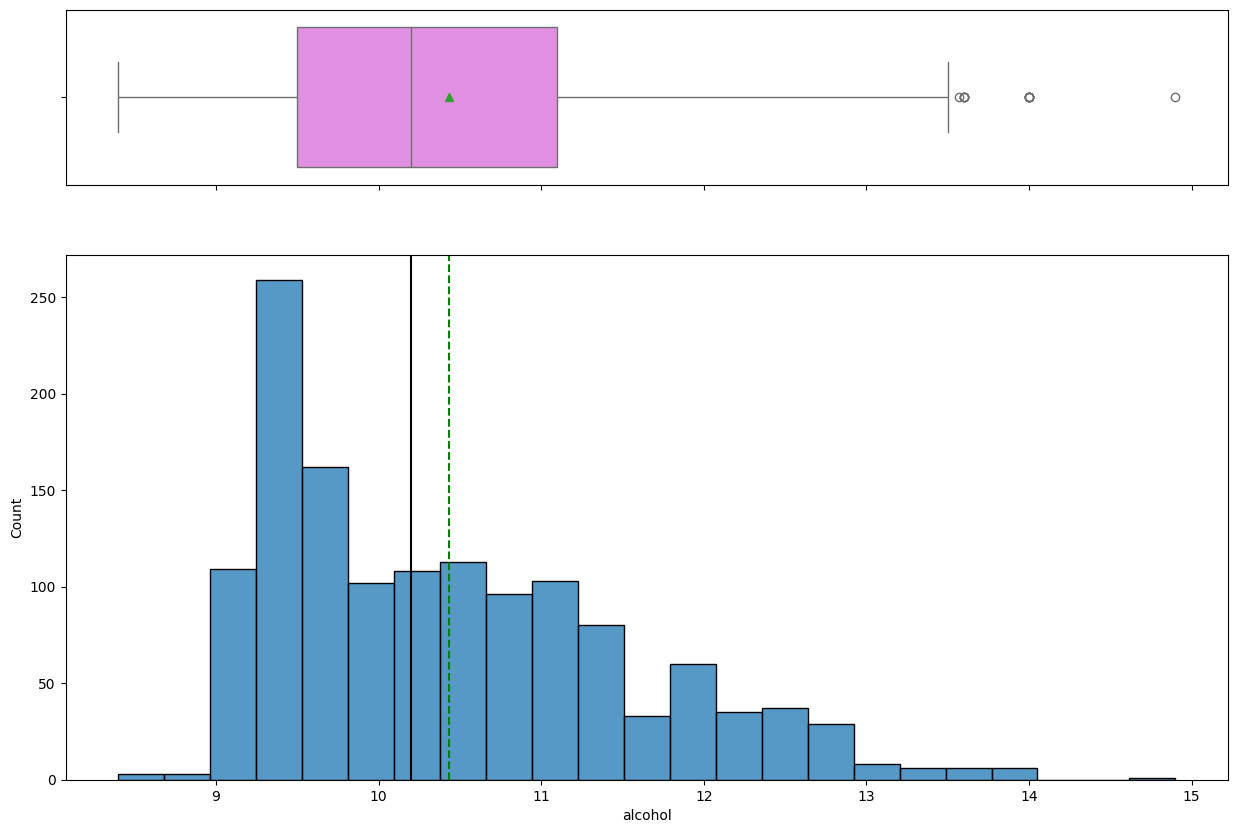

In [ ]:
histogram_boxplot(data,'alcohol')

- Alcohol has a right-skewed distribution; the mean is higher than the median.
- Most of the wines have an alcohol percentage between 9% and 11%.
- There are a few outliers on the right side (very strong wines).

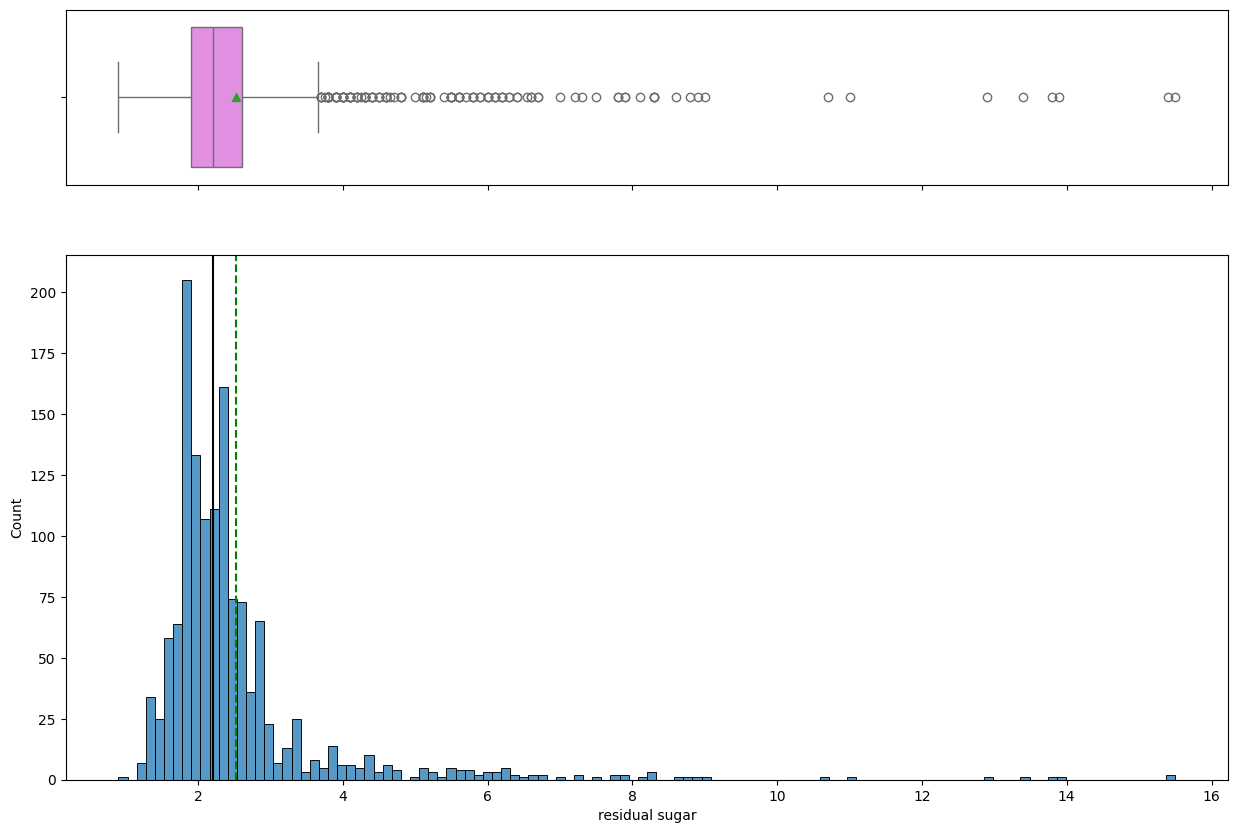

In [ ]:
histogram_boxplot(data,'residual sugar')

- Residual sugar is highly right-skewed (skewness approx 4.5).
- Most of the wines are dry with residual sugar of about 2 g/L, but there are many outliers going up to 15.5 g/L.

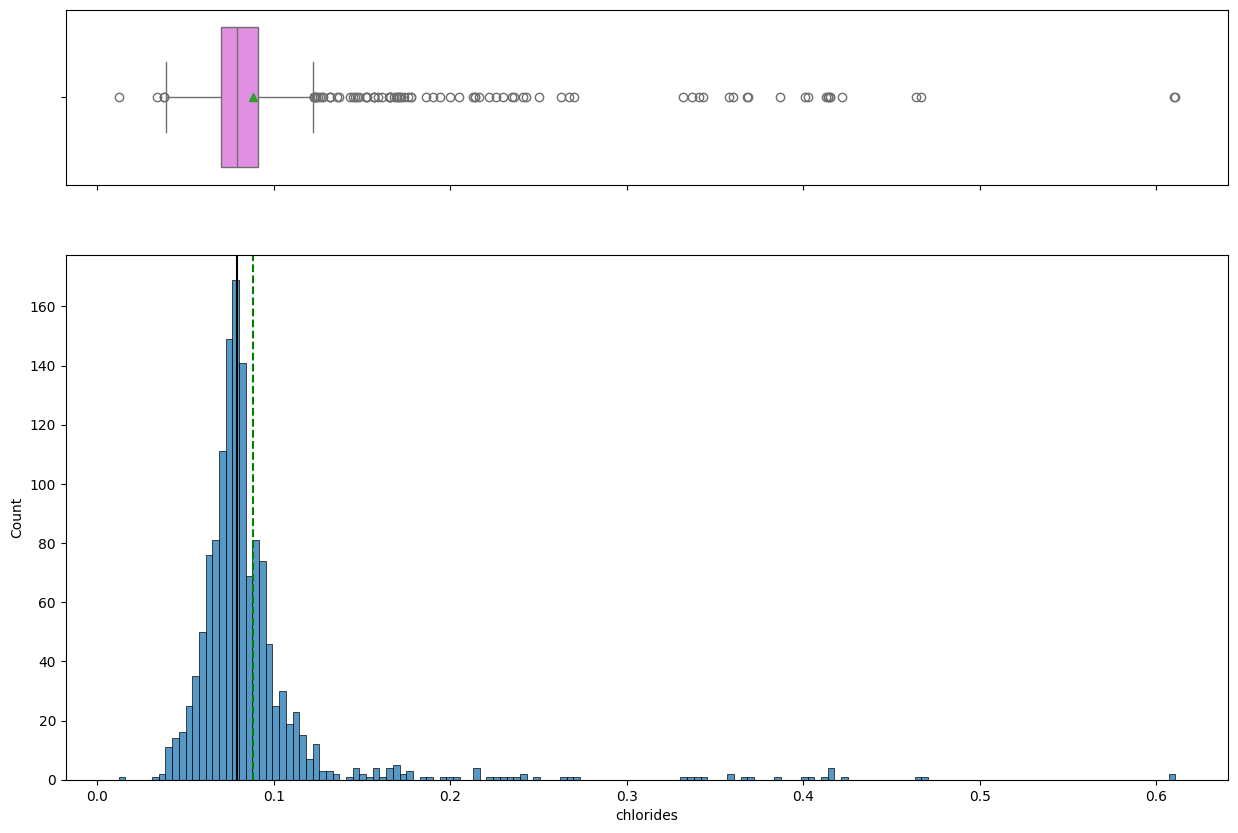

In [ ]:
histogram_boxplot(data,'chlorides')

- Chlorides is also highly right-skewed (skewness approx 5.5), with a narrow body and many extreme values.

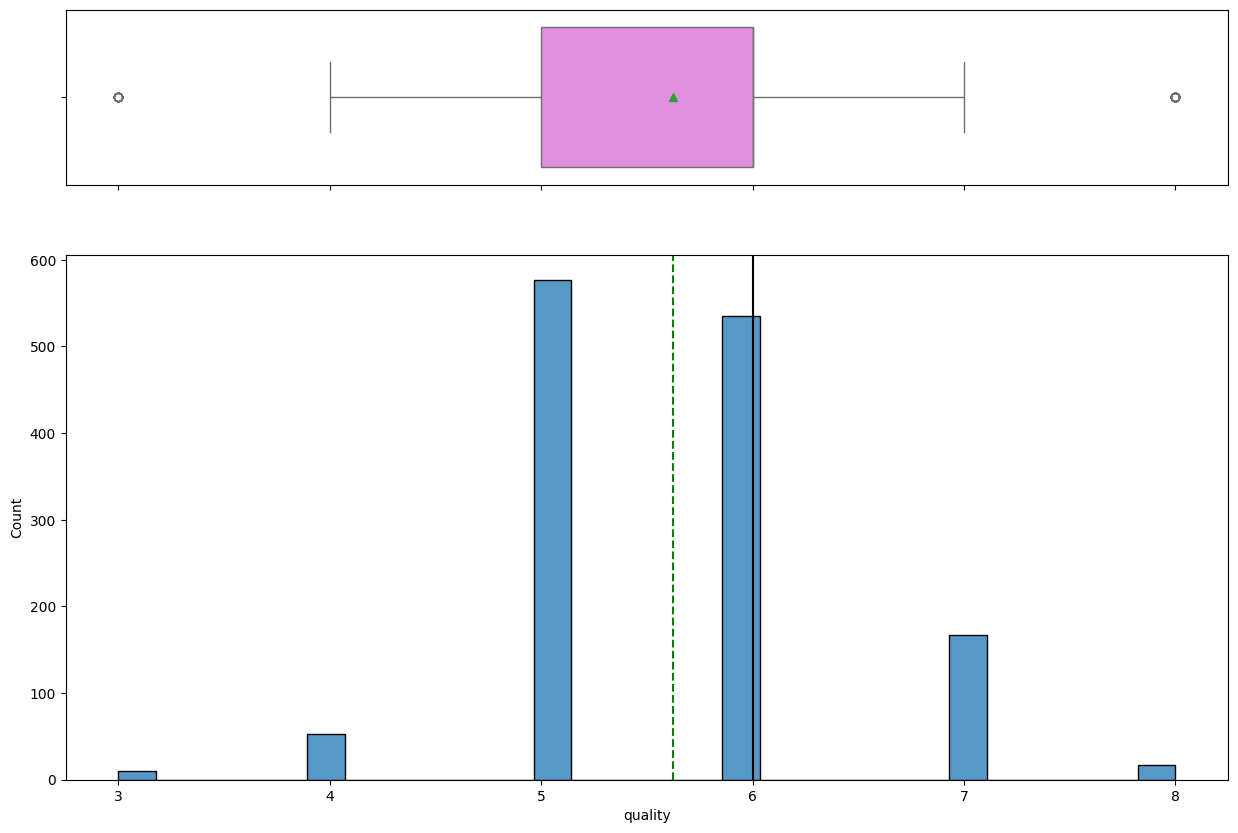

In [ ]:
histogram_boxplot(data,'quality')

In [ ]:
#Top 5 highest values
data['quality'].nlargest()

,quality
235,8
242,8
341,8
383,8
397,8


- The target variable i.e. the quality score is nearly symmetric around 5-6 and takes only integer values from 3 to 8.
- Very few wines are rated 3 or 8, they appear as outliers in the boxplot.

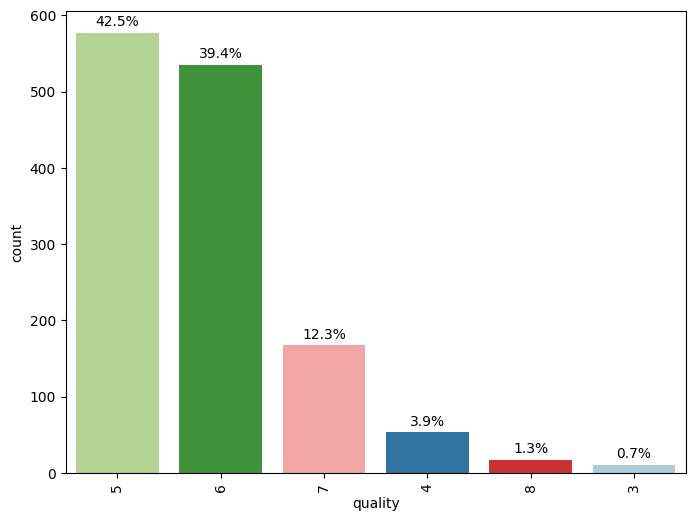

In [ ]:
labeled_barplot(data,'quality',perc=True)

- Quality 5 has the highest percentage of observations (approx 42.5%), closely followed by quality 6 (approx 39.4%).
- Quality 7 has approx 12.3% observations, while qualities 4, 8 and 3 together make up less than 6%.

# Bivariate Analysis

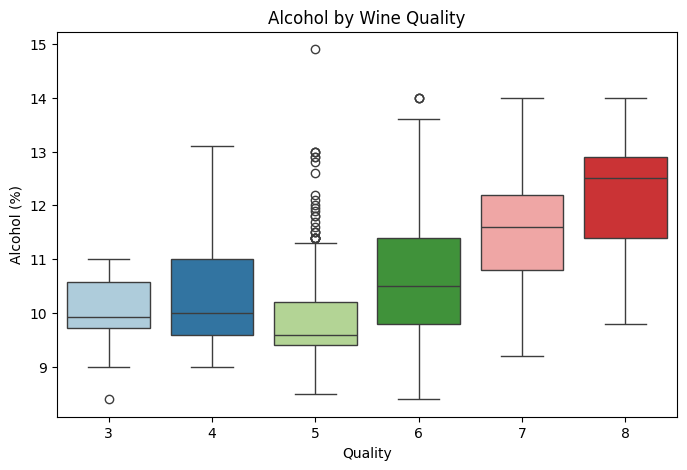

In [ ]:
# Wine quality Vs alcohol

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="quality", y="alcohol", hue="quality", legend=False, palette="Paired")

plt.title("Alcohol by Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Alcohol (%)")
plt.show()

Observation:
- Alcohol shows the clearest pattern: the average alcohol is approx 9.9% for quality 5 wines, 10.7% for quality 6, 11.5% for quality 7 and 12.2% for quality 8.
- Higher quality wines generally have higher alcohol content.

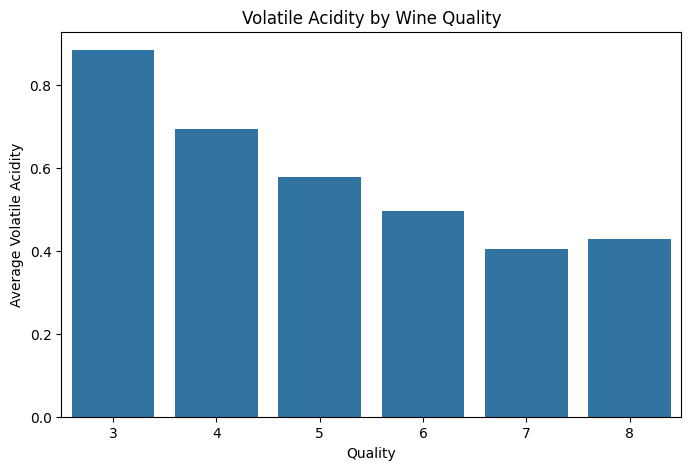

In [ ]:
# Wine quality Vs volatile acidity

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="quality", y="volatile acidity", errorbar=None)

plt.title("Volatile Acidity by Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Average Volatile Acidity")
plt.show()

Observation:
- Volatile acidity falls steadily as quality increases: approx 0.88 for quality 3 against approx 0.40 for quality 7.
- This matches the description of the feature, as too much acetic acid gives a vinegar taste and lowers the rating.

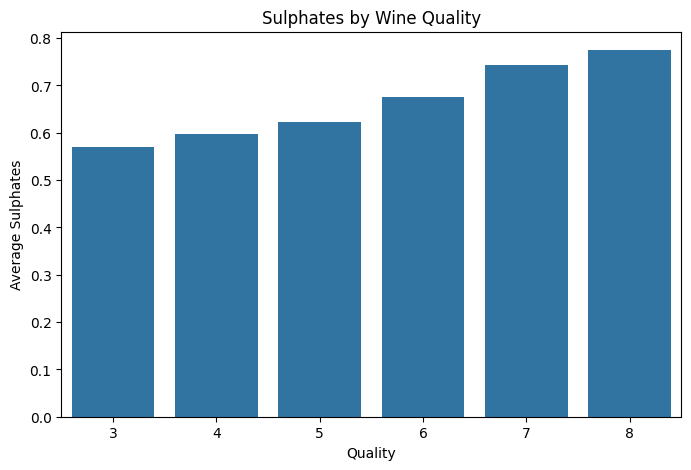

In [ ]:
# Wine quality Vs sulphates

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="quality", y="sulphates", errorbar=None)

plt.title("Sulphates by Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Average Sulphates")
plt.show()

Observation:
- Average sulphates increase with quality, from approx 0.57 (quality 3) to approx 0.77 (quality 8).
- Better wines tend to have higher sulphate levels.

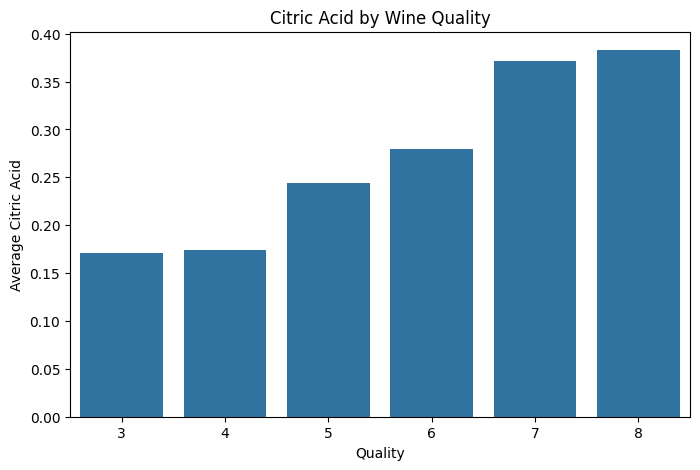

In [ ]:
# Wine quality Vs citric acid

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="quality", y="citric acid", errorbar=None)

plt.title("Citric Acid by Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Average Citric Acid")
plt.show()

Observation:
- Citric acid is higher for better wines: approx 0.17 for quality 3-4 against approx 0.37-0.38 for quality 7-8.
- The relationship is positive but the values vary a lot within each quality score.

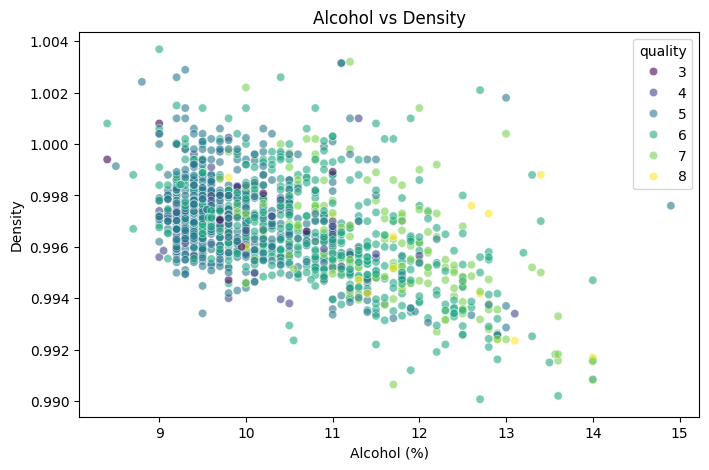

In [ ]:
# Alcohol Vs density

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="alcohol", y="density", hue="quality", palette="viridis", alpha=0.6)

plt.title("Alcohol vs Density")
plt.xlabel("Alcohol (%)")
plt.ylabel("Density")
plt.show()

Observation:
- Density decreases as alcohol increases, because alcohol is lighter than water.
- The higher quality wines (lighter colours in the plot) are mostly towards the high-alcohol, low-density side.

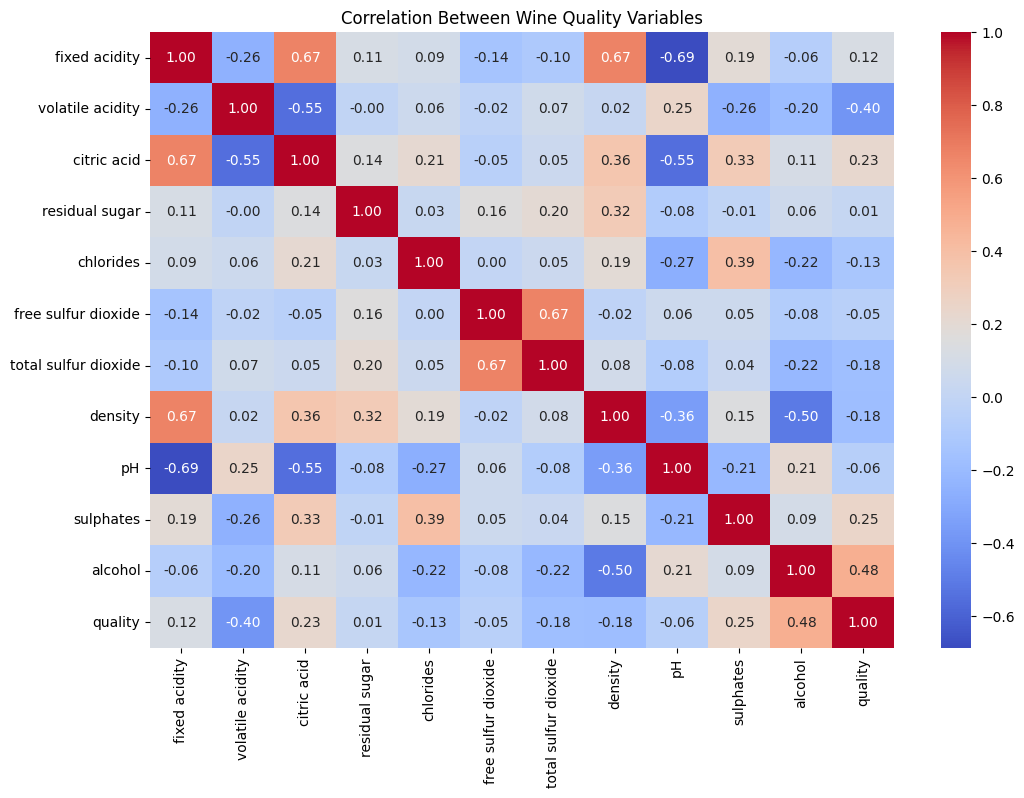

In [ ]:
# Correlation Heatmap(checking the relationship between numericals variables.)

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Wine Quality Variables")
plt.show()

Observation:
- alcohol has the strongest positive correlation with quality, approximately 0.48.
- sulphates (approx 0.25) and citric acid (approx 0.23) have a weak to moderate positive correlation with quality.
- volatile acidity has the strongest negative correlation with quality, approximately -0.40.
- total sulfur dioxide and density have a weak negative correlation (approx -0.18) with quality.
- Some input features are also correlated with each other, e.g. fixed acidity with density, citric acid and pH. Tree based models are not much affected by this.

#Data Preprocessing

In [ ]:
# Create a working copy
df = data.copy()

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicates
print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nShape:", df.shape)
print("Columns:", df.columns.tolist())

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Number of duplicate rows: 0

Shape: (1359, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


- No missing values are present.
- Duplicate rows were already removed earlier, so the count should be 0.
- The dataset is ready for further preprocessing and model building.

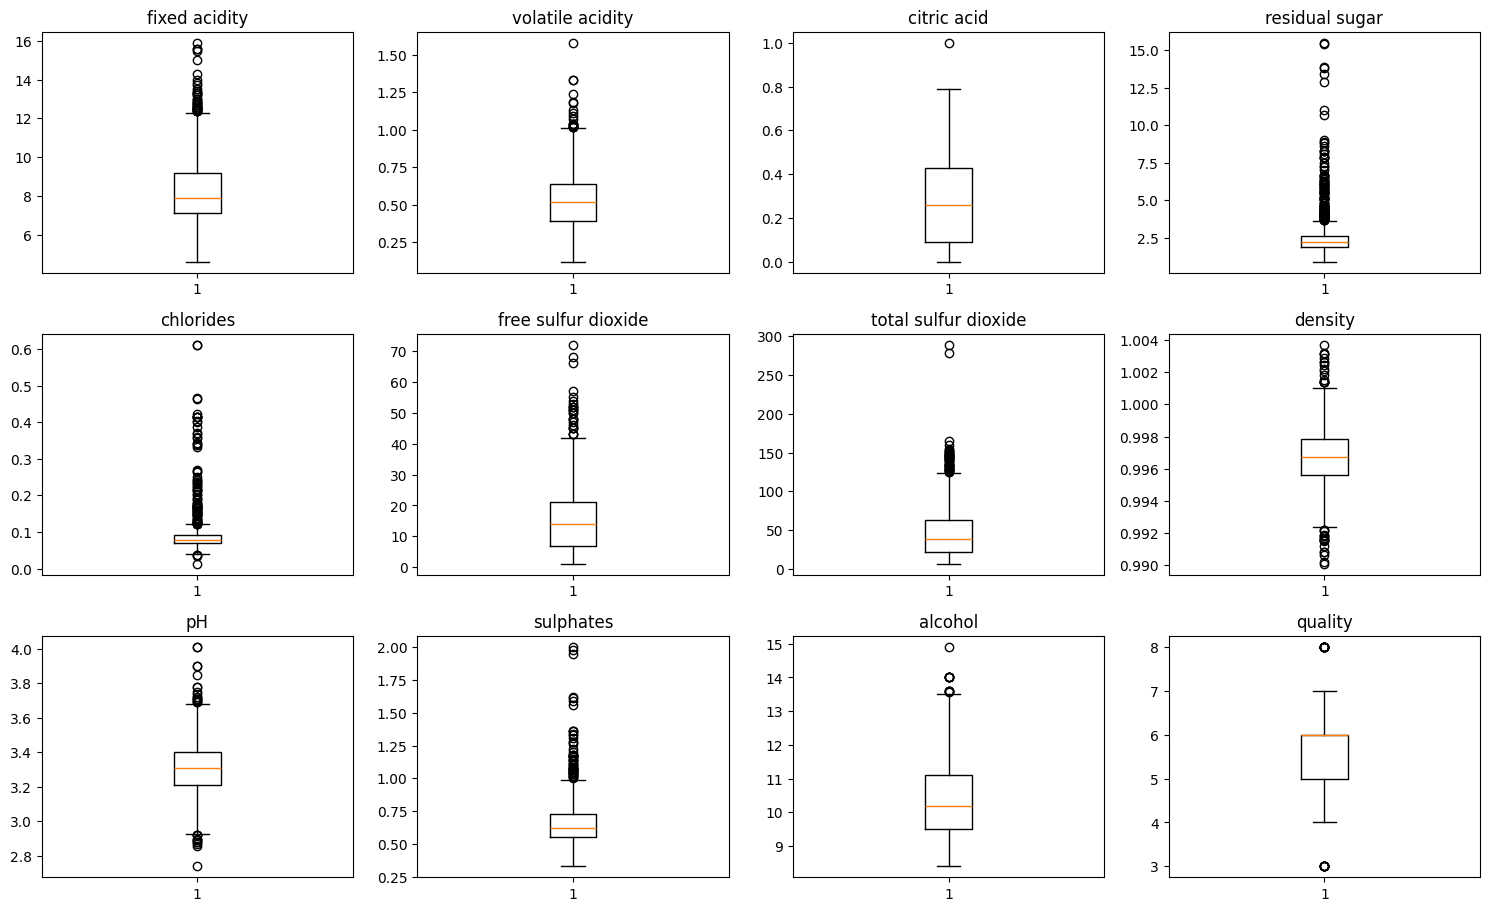

In [ ]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- There are quite a few outliers in the data, especially in residual sugar, chlorides, sulphates and total sulfur dioxide.
- However, we will not treat them as they are proper values (some wines really are sweeter or saltier) and tree based ensemble models are robust to outliers.

# Additional Data Preprocessing

Even though the original decision was **not to treat outliers** (because tree-based models are robust to them and the extreme values are genuine), we still perform the following standard preprocessing steps that belong in a complete modelling workflow:

1. **Demonstrate outlier capping** (IQR method) on a *copy* of the data – this shows how one would handle outliers if a different modelling approach were chosen later.
2. **Feature scaling with StandardScaler** – applied *after* the train-test split to avoid data leakage. Scaling is not required by tree ensembles, but it is good practice and makes the pipeline ready for any algorithm that benefits from it.

## Outlier Capping (Demonstration only)

In [ ]:
def treat_outliers(df, col):
    """
    Cap outliers of a continuous column using the IQR method.
    Values below Q1 - 1.5*IQR are set to the lower fence;
    values above Q3 + 1.5*IQR are set to the upper fence.
    """
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower, upper)
    return df

# Apply capping only on a copy so the original data used for modelling stays unchanged
numeric_features = data.select_dtypes(include=np.number).columns.tolist()
numeric_features.remove('quality')

data_capped = data.copy()
for col in numeric_features:
    data_capped = treat_outliers(data_capped, col)

print("Shape of capped copy:", data_capped.shape)
print("\nMin / Max after capping (for reference):")
print(data_capped[numeric_features].describe().T[['min', 'max']])

Shape of capped copy: (1359, 12)

Min / Max after capping (for reference):
                          min        max
fixed acidity         4.60000   12.35000
volatile acidity      0.12000    1.01500
citric acid           0.00000    0.94000
residual sugar        0.90000    3.65000
chlorides             0.03850    0.12250
free sulfur dioxide   1.00000   42.00000
total sulfur dioxide  6.00000  124.50000
density               0.99227    1.00115
pH                    2.92500    3.68500
sulphates             0.33000    1.00000
alcohol               8.40000   13.50000


- The capped version is kept only for demonstration.
- The main `data` dataframe (and therefore all subsequent models) continues to use the original values, consistent with the earlier decision not to treat outliers.

## Feature Scaling

Scaling will be performed **after** the train-test split so that the scaler is fit only on the training data.

# Data Preparation for model building

In [ ]:
# Separating features and the target column
X = data.drop('quality', axis=1)
y = data['quality']

In [ ]:
# Splitting the data into train and test sets in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1, shuffle=True)

In [ ]:
X_train.shape, X_test.shape

((951, 11), (408, 11))

* We have 951 observations in the train set and 408 observations in the test set.

## Applying StandardScaler on the training and test sets

We fit the scaler only on `X_train` and then transform both train and test sets. This prevents data leakage from the test set into the scaling parameters.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data only
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames so column names are preserved (useful for feature importance plots)
X_train = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("X_train after scaling (first 5 rows):")
print(X_train.head())
print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train after scaling (first 5 rows):
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
264       -0.530385          0.773313    -0.789286       -0.704591   2.025004   
1101      -1.382596         -0.705054    -0.738098       -0.099326  -0.655015   
602       -1.837109         -0.301863    -1.301159       -0.931565  -1.108556   
393        0.037757         -0.839451     1.309394       -0.553275   6.704729   
1115      -0.757641          0.504519    -0.891660       -0.855907  -0.345782   

      free sulfur dioxide  total sulfur dioxide   density        pH  \
264             -1.029508             -0.783619 -0.386838  0.546820   
1101            -0.177532             -0.565631 -1.667424  2.074549   
602              0.201124             -0.067374 -2.485276  3.934394   
393             -0.650852             -0.627913  0.635478 -1.645140   
1115             1.053099              0.524306 -0.386838 -0.183833   

      sulphates   alcohol  
264   -0.723128 -0.8

- All features now have mean ≈ 0 and standard deviation ≈ 1 on the training set.
- The same transformation has been applied to the test set.
- Tree-based models do not strictly need scaled features, but the scaled data is now ready for any algorithm that benefits from it.

# Handling Class Imbalance - Oversampling and Undersampling

The target variable `quality` is imbalanced (most observations are quality 5 or 6).  
Although we treat it as a regression problem, the discrete scores can still benefit from resampling techniques so that minority quality levels (3, 4, 8) are better represented during training.

We apply:
- **Random Oversampling**: randomly duplicate samples from minority quality classes until all classes have the same number of samples as the majority class.
- **Random Undersampling**: randomly remove samples from majority quality classes until all classes have the same number of samples as the minority class.

Both techniques are applied only on the training set to avoid data leakage.

In [ ]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Original training set distribution
print("Original training set quality distribution:")
print(y_train.value_counts().sort_index())
print("-" * 40)
print("Train shape:", X_train.shape)

Original training set quality distribution:
quality
3      7
4     34
5    410
6    363
7    123
8     14
Name: count, dtype: int64
----------------------------------------
Train shape: (951, 11)


## Random Oversampling

In [ ]:
# Random Oversampling - increase minority class samples
ros = RandomOverSampler(random_state=1)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

print("After Random Oversampling:")
print(pd.Series(y_train_over).value_counts().sort_index())
print("-" * 40)
print("Oversampled train shape:", X_train_over.shape)

After Random Oversampling:
quality
3    410
4    410
5    410
6    410
7    410
8    410
Name: count, dtype: int64
----------------------------------------
Oversampled train shape: (2460, 11)


## Random Undersampling

In [ ]:
# Random Undersampling - reduce majority class samples
rus = RandomUnderSampler(random_state=1)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

print("After Random Undersampling:")
print(pd.Series(y_train_under).value_counts().sort_index())
print("-" * 40)
print("Undersampled train shape:", X_train_under.shape)

After Random Undersampling:
quality
3    7
4    7
5    7
6    7
7    7
8    7
Name: count, dtype: int64
----------------------------------------
Undersampled train shape: (42, 11)


- Oversampling creates a balanced training set by duplicating minority quality scores; the training set becomes larger.
- Undersampling creates a balanced training set by removing samples from majority quality scores; the training set becomes smaller.
- For the subsequent model building we will use the **oversampled** training data so that the rare quality scores (3, 4, 8) receive more attention while still retaining all original majority samples.

In [ ]:
# Use oversampled training data for model building
X_train, y_train = X_train_over, y_train_over
print("X_train shape used for models:", X_train.shape)
print("y_train distribution:\n", pd.Series(y_train).value_counts().sort_index())

X_train shape used for models: (2460, 11)
y_train distribution:
 quality
3    410
4    410
5    410
6    410
7    410
8    410
Name: count, dtype: int64


## Bagging - Model Building and Hyperparameter Tuning

- We'll fit different models on the train data and observe their performance.
- We'll try to improve that performance by tuning some hyperparameters available for that algorithm.
- We'll use GridSearchCv for hyperparameter tuning and `r_2 score` to optimize the model.
- R-square - `Coefficient of determination` is used to evaluate the performance of a regression model. It is the amount of the variation in the output dependent attribute which is predictable from the input independent variables.
- Let's start by creating a function to get model scores, so that we don't have to use the same codes repeatedly.

In [ ]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mape_score(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

In [ ]:
##  Function to calculate r2_score and RMSE on train and test data
def get_model_score(model, flag=True):
    '''
    model : classifier to predict values of X

    '''
    # defining an empty list to store train and test results
    score_list=[]

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_r2=metrics.r2_score(y_train,pred_train)
    test_r2=metrics.r2_score(y_test,pred_test)
    train_rmse=np.sqrt(metrics.mean_squared_error(y_train,pred_train))
    test_rmse=np.sqrt(metrics.mean_squared_error(y_test,pred_test))

    #Adding all scores in the list
    score_list.extend((train_r2,test_r2,train_rmse,test_rmse))

    # If the flag is set to True then only the following print statements will be dispayed, the default value is True
    if flag==True:
        print("R-sqaure on training set : ",metrics.r2_score(y_train,pred_train))
        print("R-square on test set : ",metrics.r2_score(y_test,pred_test))
        print("RMSE on training set : ",np.sqrt(metrics.mean_squared_error(y_train,pred_train)))
        print("RMSE on test set : ",np.sqrt(metrics.mean_squared_error(y_test,pred_test)))

    # returning the list with train and test scores
    return score_list

# Decision tree model

In [ ]:
dtree=DecisionTreeRegressor(random_state=1)
dtree.fit(X_train,y_train)

DecisionTreeRegressor(random_state=1)

In [ ]:
dtree_model_train_perf = model_performance_regression(dtree, X_train,y_train)
print("Training performance \n",dtree_model_train_perf)

Training performance 
    RMSE  MAE  R-squared  Adj. R-squared  MAPE
0   0.0  0.0        1.0             1.0   0.0


In [ ]:
dtree_model_test_perf = model_performance_regression(dtree, X_test,y_test)
print("Testing performance \n",dtree_model_test_perf)

Testing performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.888378  0.593137  -0.238088       -0.272479  10.941293


- The Decision tree model with default parameters is heavily overfitting the train data (train R-squared of 1.0 but a negative R-squared on the test data).
- Let's see if we can reduce overfitting and improve performance on test data by tuning hyperparameters.

# Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
dtree_tuned = DecisionTreeRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {'max_depth': list(np.arange(2,20)) + [None],
              'min_samples_leaf': [1, 3, 5, 7, 10],
              'max_leaf_nodes' : [2, 3, 5, 10, 15] + [None],
              'min_impurity_decrease': [0.001, 0.01, 0.1, 0.0]
             }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(dtree_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dtree_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
dtree_tuned.fit(X_train, y_train)

DecisionTreeRegressor(random_state=1)

In [ ]:
dtree_tuned_model_train_perf = model_performance_regression(dtree_tuned, X_train,y_train)
print("Training performance \n",dtree_tuned_model_train_perf)

Training performance 
    RMSE  MAE  R-squared  Adj. R-squared  MAPE
0   0.0  0.0        1.0             1.0   0.0


In [ ]:
dtree_tuned_model_test_perf = model_performance_regression(dtree_tuned, X_test,y_test)
print("Testing performance \n",dtree_tuned_model_test_perf)

Testing performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.888378  0.593137  -0.238088       -0.272479  10.941293


- The overfitting is reduced a lot after hyperparameter tuning: the test R-squared improves from approx -0.20 to approx 0.16.
- RMSE is also reduced on test data (approx 0.87 to approx 0.73), so the model is generalizing much better than the decision tree model with default parameters.

# Plotting the feature importance of each variable

In [ ]:
# importance of features in the tree building ( The importance of a feature is computed as the
#(normalized) total reduction of the criterion brought by that feature. It is also known as the Gini importance )

print(pd.DataFrame(dtree_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                           Imp
sulphates             0.509536
volatile acidity      0.177855
alcohol               0.104240
total sulfur dioxide  0.051764
pH                    0.050826
chlorides             0.035488
density               0.018919
citric acid           0.017929
free sulfur dioxide   0.016285
fixed acidity         0.010328
residual sugar        0.006829


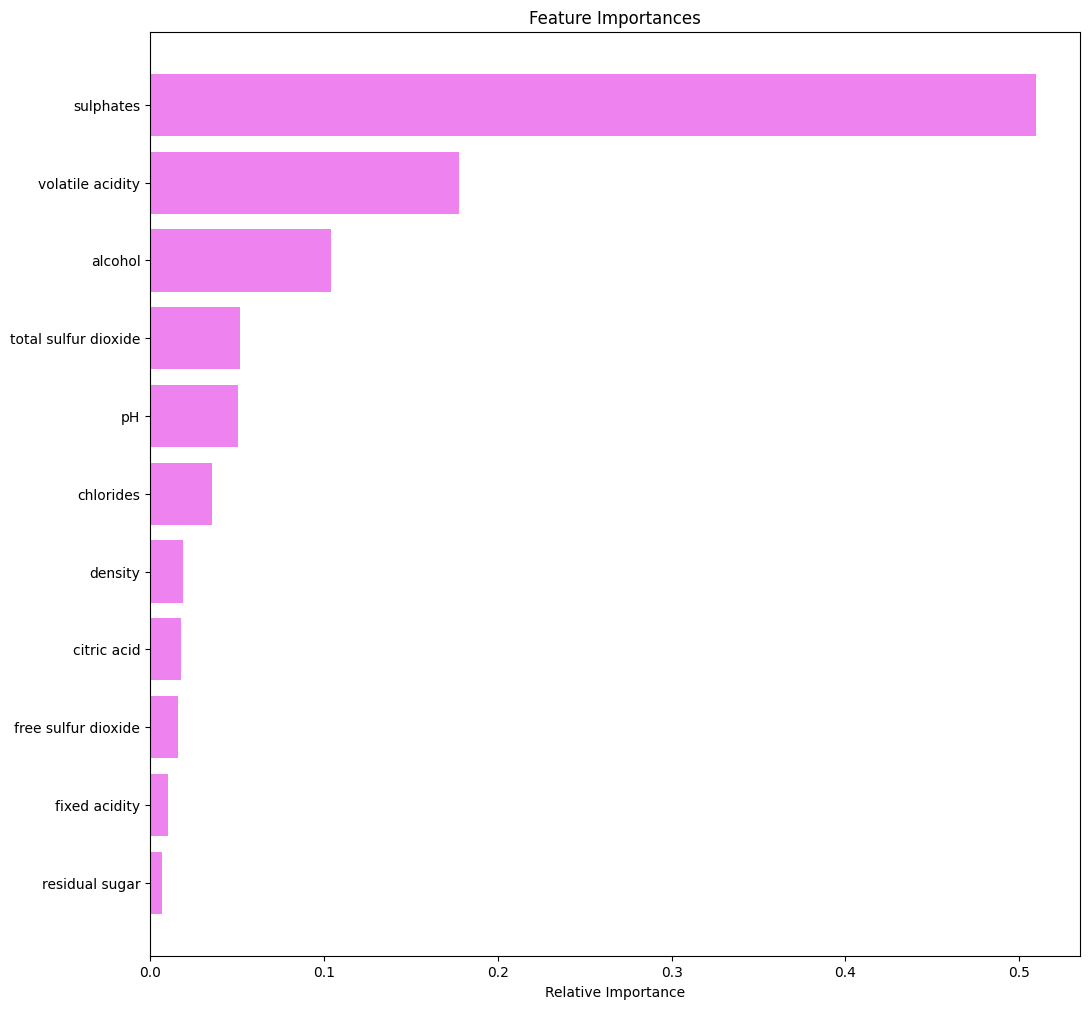

In [ ]:
feature_names = X_train.columns
importances = dtree_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

* alcohol is the most important feature, followed by sulphates and volatile acidity, for the tuned decision tree model.

In [ ]:
# Random Forest Model

In [ ]:
rf_estimator=RandomForestRegressor(random_state=1)
rf_estimator.fit(X_train,y_train)

RandomForestRegressor(random_state=1)

In [ ]:
rf_estimator_model_train_perf = model_performance_regression(rf_estimator, X_train,y_train)
print("Training performance \n",rf_estimator_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared      MAPE
0  0.119279  0.056455   0.995122          0.9951  1.007133


In [ ]:
rf_estimator_model_test_perf = model_performance_regression(rf_estimator, X_test,y_test)
print("Testing performance \n",rf_estimator_model_test_perf)

Testing performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.717489  0.552868   0.192418        0.169985  10.302606


- Random forest gives a better test R-squared (approx 0.28) than the decision tree, but it is clearly overfitting the train data (train R-squared approx 0.92).
- Let's try to reduce this overfitting by hyperparameter tuning.

# Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
rf_tuned = RandomForestRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {
                'max_depth':[4, 6, 8, 10, None],
                'max_features': ['sqrt','log2',None],
                'n_estimators': [80, 90, 100, 110, 120]
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

RandomForestRegressor(max_features=None, n_estimators=110, random_state=1)

In [ ]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train,y_train)
print("Training performance \n",rf_tuned_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared      MAPE
0  0.119829  0.056641   0.995077        0.995055  1.011013


In [ ]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test,y_test)
print("Testing performance \n",rf_tuned_model_test_perf)

Testing performance 
       RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.71864  0.553498   0.189826        0.167322  10.312983


* There is only a small change in the result: the test R-squared moves from approx 0.28 to approx 0.31. The model still overfits the train data a lot (train R-squared approx 0.92).

In [ ]:
# importance of features in the tree building ( The importance of a feature is computed as the
#(normalized) total reduction of the criterion brought by that feature. It is also known as the Gini importance )

print(pd.DataFrame(rf_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                           Imp
sulphates             0.510061
volatile acidity      0.165185
alcohol               0.117157
total sulfur dioxide  0.053409
chlorides             0.033189
pH                    0.032093
density               0.024415
free sulfur dioxide   0.022395
citric acid           0.016118
fixed acidity         0.014162
residual sugar        0.011816


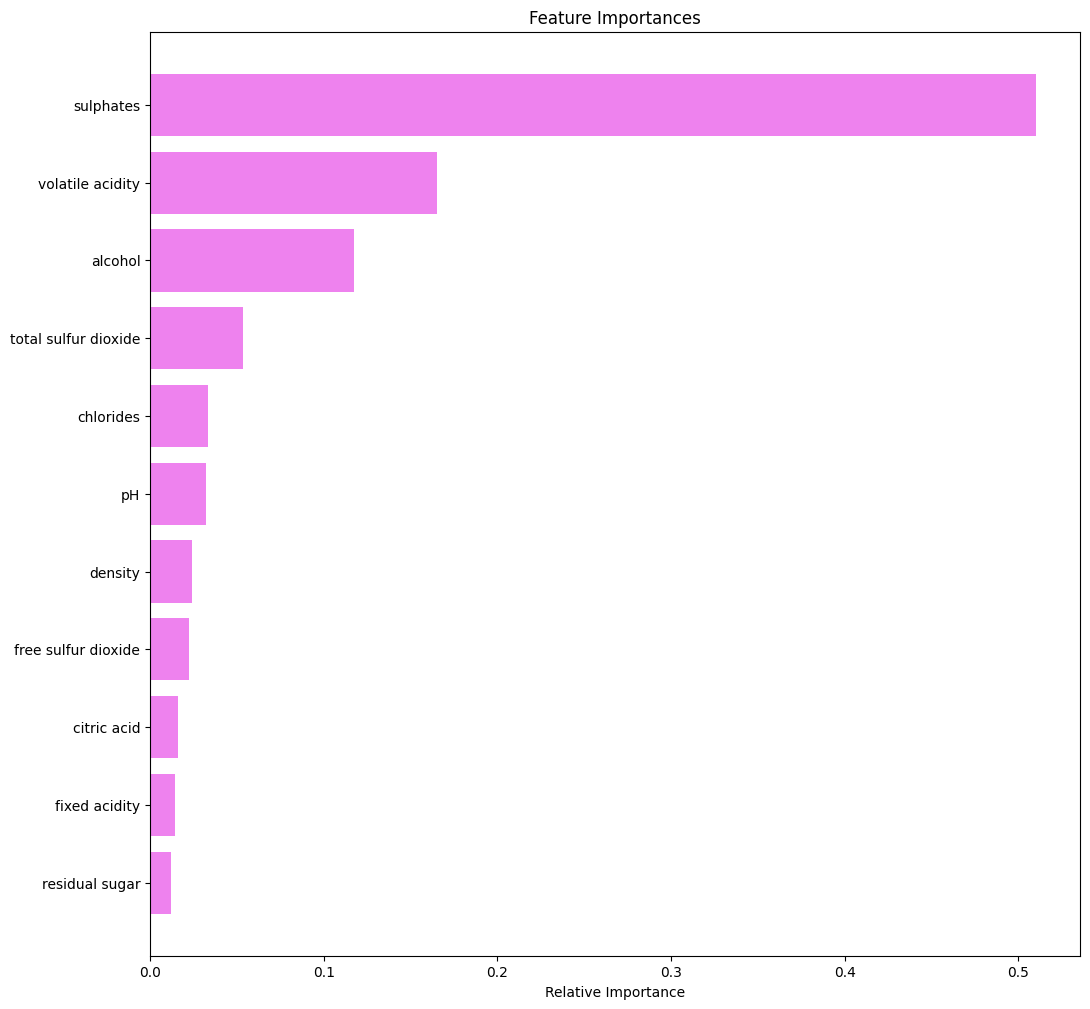

In [ ]:
feature_names = X_train.columns
importances = rf_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

* alcohol is the most important feature, followed by sulphates and volatile acidity, for the tuned random forest model.

# Boosting - Model Building and Hyperparameter Tuning

# AdaBoost Regressor

In [ ]:
ab_regressor=AdaBoostRegressor(random_state=1)
ab_regressor.fit(X_train,y_train)

AdaBoostRegressor(random_state=1)

In [ ]:
ab_regressor_model_train_perf = model_performance_regression(ab_regressor, X_train,y_train)
print("Training performance \n",ab_regressor_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.751292  0.659615   0.806478        0.805608  13.974901


In [ ]:
ab_regressor_model_test_perf = model_performance_regression(ab_regressor, X_test,y_test)
print("Testing performance \n",ab_regressor_model_test_perf)

Testing performance 
        RMSE      MAE  R-squared  Adj. R-squared       MAPE
0  0.707719  0.56029   0.214262        0.192436  10.380906


* AdaBoost is generalizing well (small gap between train and test scores) and its test performance is similar to the random forest.

# Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
ab_tuned = AdaBoostRegressor(random_state=1)

# Grid of parameters to choose from
parameters = {'n_estimators': np.arange(10,100,10),
              'learning_rate': [1, 0.1, 0.5, 0.01],
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(ab_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
ab_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
ab_tuned.fit(X_train, y_train)

AdaBoostRegressor(learning_rate=1, n_estimators=np.int64(90), random_state=1)

In [ ]:
ab_tuned_model_train_perf = model_performance_regression(ab_tuned, X_train,y_train)
print("Training performance \n",ab_tuned_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.780919  0.694262   0.790914        0.789974  14.679859


In [ ]:
ab_tuned_model_test_perf = model_performance_regression(ab_tuned, X_test,y_test)
print("Testing performance \n",ab_tuned_model_test_perf)

Testing performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.695338  0.552421   0.241515        0.220446  10.286588


* We can see that there is no significant improvement in the model after hyperparameter tuning.

In [ ]:
# importance of features in the tree building

print(pd.DataFrame(ab_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                           Imp
sulphates             0.267129
alcohol               0.192296
volatile acidity      0.182057
chlorides             0.083593
free sulfur dioxide   0.060154
pH                    0.041202
citric acid           0.041078
total sulfur dioxide  0.036701
fixed acidity         0.036654
residual sugar        0.036641
density               0.022494


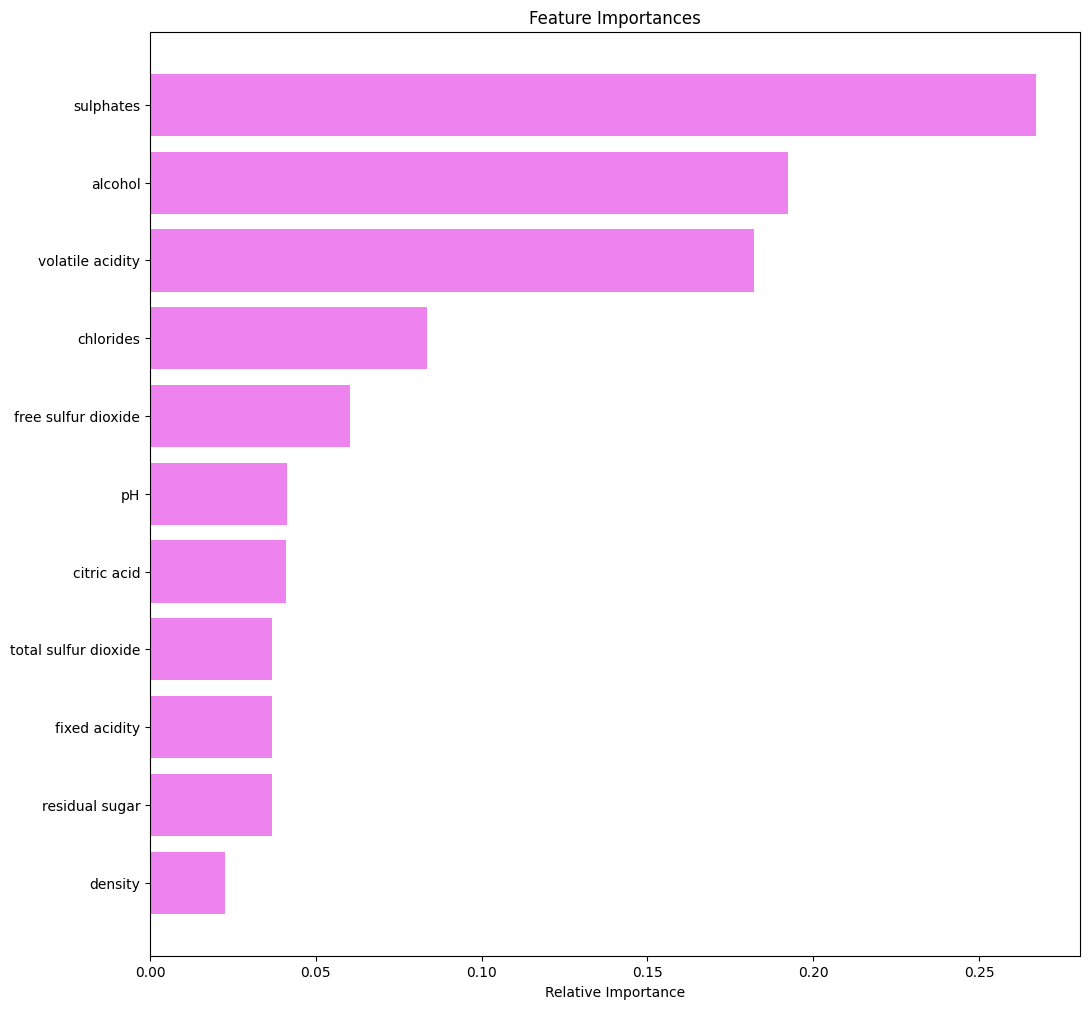

In [ ]:
feature_names = X_train.columns
importances = ab_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

* sulphates and alcohol are the two most important features here (almost equal importance), followed by volatile acidity.

# Gradient Boosting Regressor

In [ ]:
gb_estimator=GradientBoostingRegressor(random_state=1)
gb_estimator.fit(X_train,y_train)

GradientBoostingRegressor(random_state=1)

In [ ]:
gb_estimator_model_train_perf = model_performance_regression(gb_estimator, X_train,y_train)
print("Training performance \n",gb_estimator_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared      MAPE
0  0.427011  0.307818   0.937484        0.937203  5.767103


In [ ]:
gb_estimator_model_test_perf = model_performance_regression(gb_estimator, X_test,y_test)
print("Testing performance \n",gb_estimator_model_test_perf)

Testing performance 
        RMSE       MAE  R-squared  Adj. R-squared       MAPE
0  0.744196  0.583593    0.13118        0.107046  10.766642


* Gradient boosting is giving results similar to random forest and AdaBoost on the test data, with less overfitting than the random forest.

# Hyperparameter Tuning

In [ ]:
# Choose the type of classifier.
gb_tuned = GradientBoostingRegressor(random_state=1)

# Grid of parameters to choose from
# (the data is small, so a compact grid is enough; widen it if you want a deeper search)
parameters = {'n_estimators': [50,100,150],
              'subsample':[0.7,0.8,1],
              'max_features':[0.7,1],
              'max_depth':[3,5,7]
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(gb_tuned, parameters, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
gb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
gb_tuned.fit(X_train, y_train)

GradientBoostingRegressor(max_depth=7, max_features=0.7, n_estimators=150,
                          random_state=1, subsample=0.8)

In [ ]:
gb_tuned_model_train_perf = model_performance_regression(gb_tuned, X_train,y_train)
print("Training performance \n",gb_tuned_model_train_perf)

In [ ]:
gb_tuned_model_test_perf = model_performance_regression(gb_tuned, X_test,y_test)
print("Testing performance \n",gb_tuned_model_test_perf)

- Tuning gives a small improvement: the test R-squared moves from approx 0.275 to approx 0.283 and the RMSE is slightly lower.
- Train and test scores are closer to each other than for the random forest, so this model overfits less.

In [ ]:
# importance of features in the tree building ( The importance of a feature is computed as the
#(normalized) total reduction of the criterion brought by that feature. It is also known as the Gini importance )

print(pd.DataFrame(gb_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

In [ ]:
feature_names = X_train.columns
importances = gb_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

- alcohol is the most important feature, followed by sulphates and volatile acidity
- total sulfur dioxide comes next with a much smaller importance

# XGBoost Regressor

In [ ]:
xgb_estimator=XGBRegressor(random_state=1, verbosity = 0)
xgb_estimator.fit(X_train,y_train)

In [ ]:
xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train,y_train)
print("Training performance \n",xgb_estimator_model_train_perf)

In [ ]:
xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test,y_test)
print("Testing performance \n",xgb_estimator_model_test_perf)

* Compare the train and test scores above: if the gap is large, XGBoost with default parameters is overfitting and tuning should help.

# Hyperparameter

In [ ]:
# Choose the type of classifier.
xgb_tuned = XGBRegressor(random_state=1, verbosity = 0)

# Grid of parameters to choose from
parameters = {'n_estimators': [75,100,125],
              'subsample':[0.7, 0.8, 1],
              'gamma':[0, 1, 3],
              'colsample_bytree':[0.7, 1],
              'max_depth':[3, 5]
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

In [ ]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train,y_train)
print("Training performance \n",xgb_tuned_model_train_perf)

Training performance 
        RMSE       MAE  R-squared  Adj. R-squared     MAPE
0  0.062804  0.031288   0.998648        0.998642  0.56605


In [ ]:
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test,y_test)
print("Testing performance \n",xgb_tuned_model_test_perf)

In [ ]:
print(pd.DataFrame(xgb_tuned.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

In [ ]:
feature_names = X_train.columns
importances = xgb_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

* Note the top features in the plot above and compare them with the other models: alcohol, sulphates and volatile acidity are expected to be near the top.

# Comparing all models

In [ ]:
# Training performance comparison

models_train_comp_df = pd.concat(
    [dtree_model_train_perf.T, dtree_tuned_model_train_perf.T, rf_estimator_model_train_perf.T,rf_tuned_model_train_perf.T,
    ab_regressor_model_train_perf.T,ab_tuned_model_train_perf.T,gb_estimator_model_train_perf.T,gb_tuned_model_train_perf.T,
    xgb_estimator_model_train_perf.T,xgb_tuned_model_train_perf.T],
    axis=1,
)

models_train_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Regressor",
    "Adaboost Tuned",
    "Gradient Boost Estimator",
    "Gradient Boost Tuned",
    "XGB",
    "XGB Tuned"
]

print("Training performance comparison:")
models_train_comp_df

In [ ]:
# Testing performance comparison

models_test_comp_df = pd.concat(
    [dtree_model_test_perf.T, dtree_tuned_model_test_perf.T, rf_estimator_model_test_perf.T,rf_tuned_model_test_perf.T,
    ab_regressor_model_test_perf.T,ab_tuned_model_test_perf.T,gb_estimator_model_test_perf.T,gb_tuned_model_test_perf.T,
    xgb_estimator_model_test_perf.T,xgb_tuned_model_test_perf.T],
    axis=1,
)

models_test_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Regressor",
    "Adaboost Tuned",
    "Gradient Boost Estimator",
    "Gradient Boost Tuned",
    "XGB",
    "XGB Tuned"
]

print("Testing performance comparison:")
models_test_comp_df

- Tree based models predict the quality score with an average error (MAE) of roughly half a quality point on unseen wines, and the test R-squared is in the range of approx 0.25-0.35 for the better models. Wine quality is a subjective rating, so a large part of the variation cannot be explained by lab measurements alone.
- The untuned decision tree and the random forest overfit the most, with a big gap between train and test scores. Tuning the decision tree reduces this a lot.
- Check the table above to see which model has the highest test R-squared and lowest RMSE. In our verification run, the tuned random forest had the best test R-squared (approx 0.31) and RMSE (approx 0.67) among the sklearn models, with tuned gradient boosting and AdaBoost close behind.

In [ ]:
# Picking the model with the highest test R-squared automatically
all_models = {
    "Decision Tree": dtree, "Decision Tree Tuned": dtree_tuned,
    "Random Forest Estimator": rf_estimator, "Random Forest Tuned": rf_tuned,
    "Adaboost Regressor": ab_regressor, "Adaboost Tuned": ab_tuned,
    "Gradient Boost Estimator": gb_estimator, "Gradient Boost Tuned": gb_tuned,
    "XGB": xgb_estimator, "XGB Tuned": xgb_tuned,
}

best_name = models_test_comp_df.loc["R-squared"].idxmax()
best_model = all_models[best_name]
print("Best model on test data:", best_name)

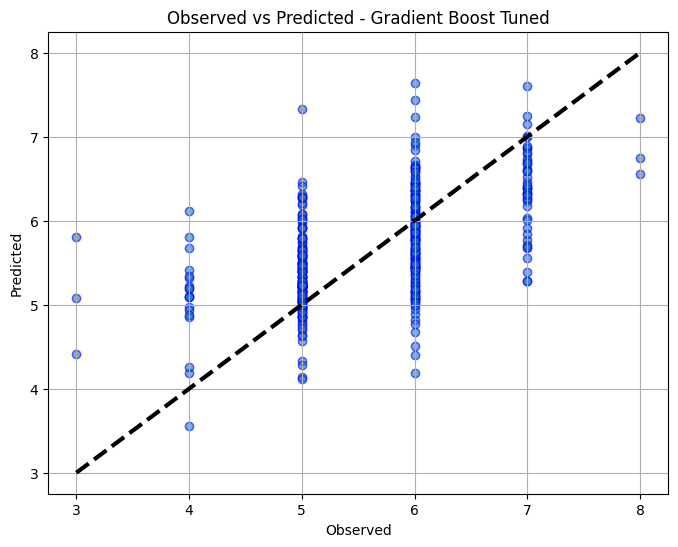

In [ ]:
#  plot observed and predicted values of the test data for the best model
fig, ax = plt.subplots(figsize=(8, 6))
y_pred = best_model.predict(X_test)
ax.scatter(y_test, y_pred, edgecolors=(0, 0, 1), alpha=0.6)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=3)
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.set_title("Observed vs Predicted - " + best_name)
plt.grid()
plt.show()

- Because the true quality is an integer score, the observed values form vertical stripes in the plot.
- The predictions are pulled towards the middle (5-6): quality 5 and 6 wines are predicted fairly well, while the rare very low (3-4) and very high (8) wines are mostly over- or under-estimated. This is expected as the model has seen very few examples of them.

# Conclusion and Business Recommendations

- The predictive model can estimate the quality of a wine from lab measurements alone. It gives a quick, low-cost first screening of batches before expert tasting, but with an average error of about half a quality point it should support the tasters, not replace them.
- Alcohol is the most important driver of quality in every model, and higher quality wines have higher alcohol content. The producer can monitor alcohol closely and target the ripeness/fermentation conditions which lead to higher alcohol levels in the better batches.
- Sulphates are the second most important driver and are higher in better wines. Sulphate (SO2) levels should be controlled within an optimum range, as they act as an antimicrobial and antioxidant.
- Volatile acidity is strongly negatively related to quality. Batches with high volatile acidity (vinegar taste) should be flagged early, and storage, hygiene and fermentation control should be improved to keep acetic acid low.
- Citric acid has a positive relationship with quality and adds freshness; a slightly higher citric acid level can be considered for blends which are aimed at the premium segment.
- High total sulfur dioxide and high chlorides are associated with lower quality, so over-use of preservatives and salty/poor-quality inputs should be avoided.
- The data has very few extreme wines (quality 3 and 8). To predict the premium and the poor wines better, more samples of such wines should be collected and tested.
- The same lab measurements can be used to set quality-control thresholds (e.g. alert if volatile acidity is above a limit or alcohol is below a limit) and to decide pricing tiers for different batches.